# **Real-Life KNN Classification Project: Student Pass/Fail**

## **1. Problem Statement**

Suppose a college wants to predict whether a student is likely to Pass or Fail based on:

Study Hours per Day
Attendance Percentage

Our target variable will be:

0 = Fail
1 = Pass

## **2. Import Libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## **3. Create the Dataset**

In [2]:
data = {
    'Age': [
        22,35,23,45,62,
        32,24,25,36,27,
        28,31,20,34,43,
        32,21,29,30,41
    ],

    'Annual_income': [
        20000,35000,23000,12000,10000,
        23000,56000,67000,30000,40000,
        23000,24400,56000,12000,5000,
        22000,78000,8000,7000,6500
    ],

    'Time_on_web' :[
        45,55,23,20,150,
        213,340,20,459,10,
        45,56,340,238,120,
        23,56,78,90,34
    ],

    'previous_purchase': [
        0, 0, 0, 0, 0,
        1, 1, 1, 1, 1,
        1, 1, 1, 1, 1,
        0, 1, 1, 1, 1
    ],

    'new_purchase' :[
        0,1,1,1,0,
        1,1,1,1,0,
        0,0,1,1,1,
        1,1,1,1,0
    ]
}

df = pd.DataFrame(data)

print(df)

    Age  Annual_income  Time_on_web  previous_purchase  new_purchase
0    22          20000           45                  0             0
1    35          35000           55                  0             1
2    23          23000           23                  0             1
3    45          12000           20                  0             1
4    62          10000          150                  0             0
5    32          23000          213                  1             1
6    24          56000          340                  1             1
7    25          67000           20                  1             1
8    36          30000          459                  1             1
9    27          40000           10                  1             0
10   28          23000           45                  1             0
11   31          24400           56                  1             0
12   20          56000          340                  1             1
13   34          12000          23

## **4. Separate Features and Target**

In [3]:
X = df[['Time_on_web', 'previous_purchase']]
y = df['new_purchase']

## **5. Visualize the Data**

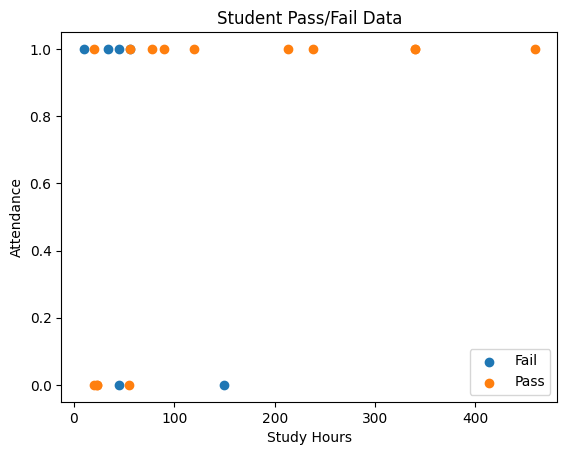

In [4]:
plt.scatter(
    df[df['new_purchase'] == 0]['Time_on_web'],
    df[df['new_purchase'] == 0]['previous_purchase'],
    label='Fail'
)

plt.scatter(
    df[df['new_purchase'] == 1]['Time_on_web'],
    df[df['new_purchase'] == 1]['previous_purchase'],
    label='Pass'
)

plt.xlabel('Study Hours')
plt.ylabel('Attendance')
plt.title('Student Pass/Fail Data')
plt.legend()
plt.show()

## **6. Split Data into Training and Testing**

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## **7. Feature Scaling**
This step is very important for KNN.

In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

## **8. Create the KNN Model**

In [7]:
knn = KNeighborsClassifier(n_neighbors=3)

## **9. Train the Model**

In [8]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

## **10. Make Predictions**

In [9]:
y_pred = knn.predict(X_test)

print(y_pred)

[1 1 1 1]


## **11. Check Accuracy**

In [10]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.75


## **12. Confusion Matrix**

In [11]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[0 1]
 [0 3]]


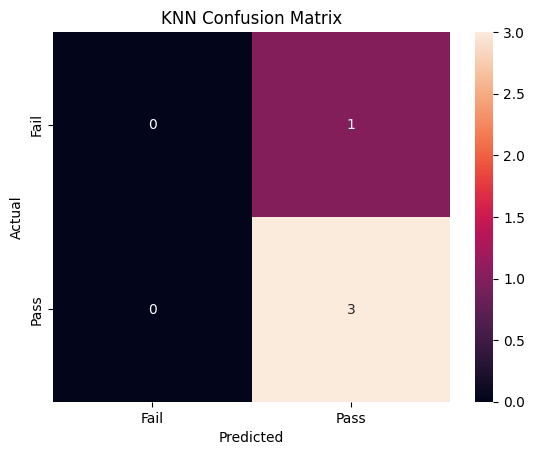

In [12]:
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('KNN Confusion Matrix')
plt.show()

## **13. Classification Report**

In [13]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.75      1.00      0.86         3

    accuracy                           0.75         4
   macro avg       0.38      0.50      0.43         4
weighted avg       0.56      0.75      0.64         4



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## **14. Predict a New Student**

Step 1 — Create the new student's data

In [14]:
new_customer= [[50, 1]]

Step 2 — Scale the data

In [15]:
new_customer_scaled = scaler.transform(new_customer)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Step 3 — Predict

In [16]:
prediction = knn.predict(new_customer_scaled)

print(prediction)

[0]


## **15. Make the Output User-Friendly**

In [17]:
if prediction[0] == 1:
    print("Prediction: Student is likely to PASS")
else:
    print("Prediction: Student is likely to FAIL")

Prediction: Student is likely to FAIL


## **16. See the Nearest Students**

This is a very useful part

In [18]:
distances, indices = knn.kneighbors(new_customer_scaled)

print("Distances:")
print(distances)

print("\nNearest Student Indices:")
print(indices)

Distances:
[[0.03692239 0.04430686 0.04430686]]

Nearest Student Indices:
[[13  2  5]]
